# The Neural Bigram Language Model

### A first step from matrix factorization to learned word embeddings

---
Traditional representation has its limitations, especially its **local representation** ; each input is represented independently, with limited contextual information.

**Motivation** : The idea is to incorporate more sophisticated techniques to extract meaningful and informative features while : 
- Keeping the representation dense & compact.
- Capturing rich semantic information without relying on knowledge graph. 

Where Latent Semantic Analysis(LSA) discovers a static semantic space in one shot by factorizing a
global term-document matrix, a **neural bigram language model** learns a comparable
low-dimensional word representation incrementally, by training a network -- via ordinary
gradient descent rather than a matrix decomposition -- to predict a word from its immediate
neighbor.

**Contents**

1. [From counting to learning: the bigram language model](#1)
2. [Neural architecture](#2)
3. [A medium-small corpus](#3)
4. [Tokenization and vocabulary construction](#4)
5. [Building the training pairs](#5)
6. [Implementing the model](#6)
7. [Training](#7)
8. [Inspecting what the model learned](#8)
9. [Discussion, and toward word2vec](#9)


## 1. From counting to learning: the bigram language model <a id="1"></a>

A **bigram language model** makes the Markov assumption that the next word depends only on the
current word:

$$
P(w_1, \dots, w_T) = \prod_{t=1}^{T} P(w_t \mid w_{t-1}).
$$

The classical way to estimate $P(w_t \mid w_{t-1})$ is simply to count: divide how often the
pair $(w_{t-1}, w_t)$ occurs by how often $w_{t-1}$ occurs, with some smoothing for pairs never
seen in training. This works, but the resulting table has one independent parameter per pair of
words -- it has no notion that "cat" and "dog" might behave similarly, and it cannot generalize
at all to a pair it never saw.

A **neural** bigram model keeps the same Markov factorization, but replaces the lookup table
with a parametric function $f_\theta(w_{t-1})$ that outputs a full probability distribution over
the vocabulary for the next word. Because $\theta$ is shared across every word in the
vocabulary, and because words will be represented as continuous vectors rather than discrete
symbols, the model can generalize: two context words that behave similarly in the training data
are free to end up with similar internal representations, and therefore similar predictions --
exactly the distributional intuition behind LSA, now learned rather than factorized.

## 2. Neural architecture <a id="2"></a>

$$
\text{Input (one-hot)} \;\longrightarrow\; \text{Embedding } (|V| \times d) \;\longrightarrow\;
\text{Output layer } (d \times |V|) \;\longrightarrow\; \text{Softmax}
$$

Let $V$ denote the vocabulary and $|V|$ its size. Given a context word $w_{t-1}$, encode it as a
one-hot vector $\mathbf{x} \in \{0,1\}^{|V|}$ (all zeros except a $1$ at the index of $w_{t-1}$).

**Embedding layer.** A matrix $E \in \mathbb{R}^{|V| \times d}$ holds one $d$-dimensional row per
vocabulary word. Because $\mathbf{x}$ is one-hot,

$$
\mathbf{h} = E^{T}\mathbf{x} = E_{[w_{t-1}]} \in \mathbb{R}^{d}
$$

is simply *row $w_{t-1}$ of $E$* -- multiplying by a one-hot vector is equivalent to a table
lookup. This is precisely why, in practice, embedding layers are implemented as index lookups
rather than literal matrix multiplications; we keep the one-hot formulation here only because it
makes the architecture diagram above exact.

**Output layer.** A second matrix $W \in \mathbb{R}^{d \times |V|}$ projects the embedding back
up to vocabulary size:

$$
\mathbf{z} = \mathbf{h}^{T} W \in \mathbb{R}^{|V|}.
$$

**Softmax.** The logits $\mathbf{z}$ are turned into a probability distribution over the next
word,

$$
\hat{y}_i = \frac{e^{z_i}}{\sum_{j=1}^{|V|} e^{z_j}}, \qquad i = 1, \dots, |V|.
$$

**Loss.** Training minimizes the cross-entropy between $\hat{\mathbf{y}}$ and the true next word
$w_t$ (itself one-hot, $\mathbf{y}$):

$$
\mathcal{L} = -\log \hat{y}_{w_t}.
$$

Two design choices are worth flagging explicitly, since they distinguish this model from LSA:

- $E$ and $W$ are **two separate matrices**, learned jointly and asymmetrically, rather than the
  two factors $U_k$ and $V_k$ of a single, shared decomposition of one matrix.
- The whole model is trained **incrementally**, one $(w_{t-1}, w_t)$ pair at a time, by gradient
  descent -- there is no single global matrix ever explicitly formed or factorized.

The gradients are short to derive by hand and are implemented explicitly in Section 6, precisely
because this derivation is the mathematical core of word2vec itself (Section 9).

## 3. A medium-small corpus <a id="3"></a>

To keep every step of training fully inspectable, we use a short, self-contained, original
passage (rather than a large external corpus) -- small enough that the whole vocabulary, every
training pair, and every gradient step can be reasoned about directly, yet large enough to
contain genuine, learnable bigram structure (repeated words such as *word*, *words*, *model*,
*meaning*, *representation* recur in different local contexts throughout the passage).

In [1]:
TEXT = """
Language is a curious inheritance: every word we speak was once spoken by
someone else, in some other sentence, carrying some other shade of meaning.
A word rarely means anything on its own; it means something only in the
company of other words. The context in which a word appears shapes how we
understand that word, and the words that a word keeps company with become,
over time, part of its very identity. This simple observation, that a word
is known by the company it keeps, is the foundation of distributional
semantics. A neural language model formalizes this observation in a very
direct way: it learns to guess a word from its neighbor, and in the process
of learning to guess well, it discovers a compact numerical representation
for every word in its vocabulary. Two words that tend to appear near the
same neighbors will end up with similar representations, because the model
has no other way to explain their similar behavior. This is the same
intuition that motivated latent semantic analysis, except that instead of
factorizing a single global matrix all at once, a neural model refines its
representation gradually, one small prediction at a time, one pair of
neighboring words at a time. Over many such small corrections, the
representation slowly settles into a space where semantic relationships
between words become geometric relationships between vectors: words that
are used similarly end up living close together.
"""

print(f"{len(TEXT.split())} raw whitespace-separated tokens")

237 raw whitespace-separated tokens


## 4. Tokenization and vocabulary construction <a id="4"></a>

We use a lightweight, dependency-free pipeline, consistent with the rest of this series:

1. Split the passage into sentences.
2. Lowercase and extract alphabetic tokens (dropping punctuation) with a regular expression.
3. Wrap each sentence with explicit boundary tokens `<s>` and `</s>`, so the model also learns
   which words plausibly *start* and *end* a sentence -- itself a (context, next word) pair like
   any other.
4. Collect the resulting tokens into a sorted vocabulary and two lookup dictionaries,
   `word2idx` and `idx2word`.

In [2]:
import re
import numpy as np

def split_into_sentences(text):
    text = re.sub(r"\s+", " ", text).strip()
    return [s.strip() for s in re.split(r"(?<=[.!?:;])\s+", text) if s.strip()]

def tokenize(sentence):
    return re.findall(r"[a-z']+", sentence.lower())

BOS, EOS = "<s>", "</s>"

sentences = split_into_sentences(TEXT)
tokenized_sentences = [[BOS] + tokenize(s) + [EOS] for s in sentences]

print(f"{len(sentences)} sentences, e.g.:")
print(" ", tokenized_sentences[0])

12 sentences, e.g.:
  ['<s>', 'language', 'is', 'a', 'curious', 'inheritance', '</s>']


In [3]:
vocab = sorted(set(tok for sent in tokenized_sentences for tok in sent))
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
VOCAB_SIZE = len(vocab)

print(f"Vocabulary size |V| = {VOCAB_SIZE}")
print("Sample of the vocabulary:", vocab[:12], "...")

Vocabulary size |V| = 134
Sample of the vocabulary: ['</s>', '<s>', 'a', 'all', 'analysis', 'and', 'anything', 'appear', 'appears', 'are', 'at', 'because'] ...


## 5. Building the training pairs <a id="5"></a>

Sliding a window of size 2 over each (boundary-tagged) sentence produces every
$(w_{t-1}, w_t)$ bigram the model will be trained on. Pairs never cross a sentence boundary, so
the model is never asked to predict the first word of a sentence from the last word of the
previous one.

In [4]:
pairs = []
for sent in tokenized_sentences:
    for context_word, target_word in zip(sent[:-1], sent[1:]):
        pairs.append((word2idx[context_word], word2idx[target_word]))

pairs = np.array(pairs)
print(f"{len(pairs)} training pairs, e.g.:")
for ctx_idx, tgt_idx in pairs[:5]:
    print(f"  ({idx2word[ctx_idx]!r} -> {idx2word[tgt_idx]!r})")

249 training pairs, e.g.:
  ('<s>' -> 'language')
  ('language' -> 'is')
  ('is' -> 'a')
  ('a' -> 'curious')
  ('curious' -> 'inheritance')


## 6. Implementing the model <a id="6"></a>

We implement the forward pass, loss, and gradients exactly as derived in Section 2, in plain
NumPy, so that nothing about the computation is hidden behind a deep learning framework. Because
$\mathbf{h} = E_{[i]}$ is a lookup rather than a matrix product, and because only one row of $E$
is ever read per training example, the backward pass also only ever needs to *update* that one
row of $E$ -- the gradient with respect to every other row is exactly zero. This sparsity of
updates is the computational property that later makes word2vec practical at very large
vocabulary sizes (Section 9).

Concretely, with $\hat{\mathbf{y}} = \mathrm{softmax}(\mathbf{z})$ and true next-word index
$t$, the gradient of the cross-entropy loss with respect to the logits has the famously simple
form $\partial \mathcal{L}/\partial \mathbf{z} = \hat{\mathbf{y}} - \mathbf{y}$ (predicted minus
true one-hot), from which the gradients with respect to $W$ and the single active row of $E$
follow directly from the chain rule.

In [5]:
class NeuralBigramModel:
    """Minimal neural bigram language model: one-hot -> embedding -> output -> softmax."""

    def __init__(self, vocab_size, embedding_dim, seed=42):
        rng = np.random.default_rng(seed)
        scale = 0.1
        self.E = rng.normal(0, scale, size=(vocab_size, embedding_dim))  # |V| x d
        self.W = rng.normal(0, scale, size=(embedding_dim, vocab_size))  # d x |V|

    @staticmethod
    def softmax(z):
        z = z - z.max()               # numerical stability
        exp_z = np.exp(z)
        return exp_z / exp_z.sum()

    def forward(self, context_idx):
        h = self.E[context_idx]        # embedding lookup, (d,)
        z = h @ self.W                 # output layer,      (|V|,)
        y_hat = self.softmax(z)        # softmax,           (|V|,)
        return h, y_hat

    def train_step(self, context_idx, target_idx, lr):
        h, y_hat = self.forward(context_idx)
        loss = -np.log(y_hat[target_idx] + 1e-12)

        dz = y_hat.copy()
        dz[target_idx] -= 1.0          # dL/dz = y_hat - one_hot(target)

        dW = np.outer(h, dz)           # dL/dW,             (d, |V|)
        dh = self.W @ dz               # dL/dh,             (d,)

        self.W -= lr * dW
        self.E[context_idx] -= lr * dh  # only row `context_idx` of E is ever touched

        return loss

    def predict_next(self, word, word2idx, idx2word, top_k=5):
        _, y_hat = self.forward(word2idx[word])
        top_idx = np.argsort(y_hat)[::-1][:top_k]
        return [(idx2word[i], float(y_hat[i])) for i in top_idx]

## 7. Training <a id="7"></a>

We train with plain (per-example) stochastic gradient descent, re-shuffling the pairs every
epoch, and track the average cross-entropy loss per epoch. As a sanity check, a completely
untrained model should incur a loss close to $\log|V|$ (the cross-entropy of a uniform guess
over the vocabulary); a well-trained model should drop substantially below that.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

EMBEDDING_DIM = 16
N_EPOCHS = 300
LEARNING_RATE = 0.05

model = NeuralBigramModel(VOCAB_SIZE, EMBEDDING_DIM)
rng = np.random.default_rng(0)

epoch_losses = []
for epoch in range(N_EPOCHS): # Using stochatic gradient descent
    order = rng.permutation(len(pairs))
    total_loss = 0.0
    for i in order:
        context_idx, target_idx = pairs[i]
        total_loss += model.train_step(context_idx, target_idx, LEARNING_RATE)
    epoch_losses.append(total_loss / len(pairs))

print(f"Uniform-guess baseline loss: log|V| = {np.log(VOCAB_SIZE):.3f}")
print(f"Loss after epoch 1:          {epoch_losses[0]:.3f}")
print(f"Loss after epoch {N_EPOCHS}:        {epoch_losses[-1]:.3f}")

Uniform-guess baseline loss: log|V| = 4.898
Loss after epoch 1:          4.899
Loss after epoch 300:        0.973


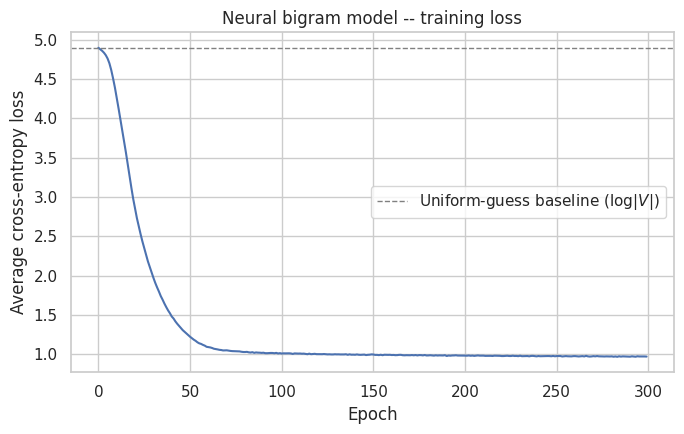

In [7]:
plt.figure(figsize=(7, 4.5))
plt.plot(epoch_losses)
plt.axhline(np.log(VOCAB_SIZE), color="grey", linestyle="--", linewidth=1,
            label=r"Uniform-guess baseline ($\log|V|$)")
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("Neural bigram model -- training loss")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Inspecting what the model learned <a id="8"></a>

### 8.1 Next-word predictions

For a handful of context words, we read off the model's top-5 predicted next words directly
from $\hat{\mathbf{y}}$. Given how small and repetitive the training corpus is, the model should
essentially memorize the handful of bigram continuations it saw -- which is exactly the point:
it recovers, from gradient descent alone, associations such as *words -> that* (from "words
that ..." appearing several times) or *meaning -> \</s\>* (the corpus literally ends a sentence
right after the word "meaning").

In [8]:
for query_word in ["word", "words", "meaning", "model", "language", BOS]:
    predictions = model.predict_next(query_word, word2idx, idx2word, top_k=5)
    formatted = ", ".join(f"{w!r} ({p:.2f})" for w, p in predictions)
    print(f"{query_word!r:>10s} -> {formatted}")

    'word' -> 'and' (0.15), 'we' (0.13), 'appears' (0.13), 'is' (0.12), 'from' (0.12)
   'words' -> 'that' (0.52), '</s>' (0.17), 'at' (0.15), 'become' (0.15), 'similar' (0.00)
 'meaning' -> '</s>' (0.99), 'that' (0.00), 'part' (0.00), 'to' (0.00), 'become' (0.00)
   'model' -> 'formalizes' (0.35), 'has' (0.32), 'refines' (0.31), 'analysis' (0.00), 'relationships' (0.00)
'language' -> 'is' (0.54), 'model' (0.43), 'company' (0.01), 'simple' (0.01), 'language' (0.00)
     '<s>' -> 'this' (0.17), 'it' (0.16), 'a' (0.16), 'words' (0.10), 'two' (0.08)


### 8.2 Geometry of the learned embedding space

The rows of $E$ are, by construction, the model's learned word vectors. We project them to 2D
with PCA and inspect whether words that played similar distributional roles in the corpus
(e.g. *word* / *words*, or *model* / *representation*) end up nearby -- the same kind of
qualitative check we used for the LSA document-topic space in the previous notebook, now applied
to *word* vectors instead of *document* vectors.

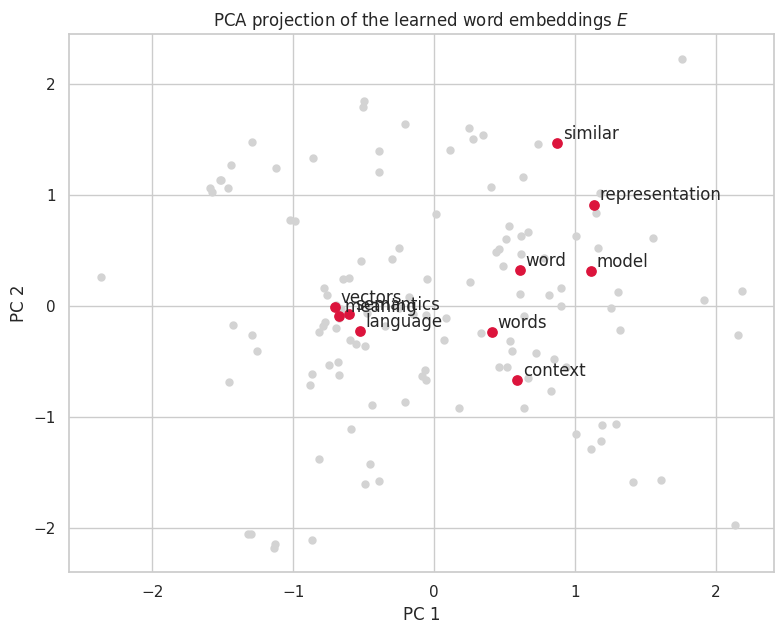

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
E_2d = pca.fit_transform(model.E)

# Highlight a handful of thematically related content words; grey out the rest,
# and drop the boundary tokens from the plot since they dominate by frequency alone.
highlight = {"word", "words", "meaning", "model", "language", "representation",
             "context", "semantics", "vectors", "similar"}
mask_special = np.array([w in (BOS, EOS) for w in vocab])

plt.figure(figsize=(8, 6.5))
plt.scatter(E_2d[~mask_special, 0], E_2d[~mask_special, 1], color="lightgrey", s=25)
for w in highlight:
    i = word2idx[w]
    plt.scatter(E_2d[i, 0], E_2d[i, 1], color="crimson", s=45, zorder=3)
    plt.annotate(w, (E_2d[i, 0], E_2d[i, 1]), xytext=(4, 3), textcoords="offset points")

plt.title("PCA projection of the learned word embeddings $E$")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.tight_layout()
plt.show()

With a training corpus this small the geometry should be read qualitatively rather than
over-interpreted: a handful of bigram pairs is not enough data to reliably separate fine-grained
shades of meaning. What we can already observe is the mechanism itself working end to end -- a
one-hot input turned, through nothing but repeated gradient corrections on next-word prediction,
into a continuous vector space with *some* non-trivial local structure. Scaling the same
mechanism up to a realistic corpus, a larger context window, and a smarter training objective is
exactly the subject of Section 9.

## BONUS : Practical approach : using PyTorch 

The (previous) implementation from scratch is designed to recall some of the fundamentals of Neural Network, as well as intriguing new readers to discover by themselves(for now because i plan on making a new series for more in-depth notions) the beauty of the mathematical framework behind the first unit of deep learning.

Moving now to more practical one using the notorious library `Pytorch` 


We convert our Numpy array(dataset) to Pytorch tensor

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

pairs = torch.tensor(pairs, dtype=torch.long)

# Inputs: context word IDs
X = pairs[:, 0]

# Targets: next word IDs
Y = pairs[:, 1]

vocab_size = len(word2idx)

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Vocabulary size:", vocab_size)

The Bigram class would be : 

In [ ]:
class BigramLanguageModel(nn.Module):

    def __init__(self, vocab_size, embedding_dim):
        super().__init__()

        # Embedding matrix: (V, d)
        self.token_embedding_table = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        # Projection from embedding space to vocabulary space
        self.linear = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(self, context, targets=None):

        # context: (B,)
        # Each element is a word index

        # Embedding lookup: (B, D)
        embeddings = self.token_embedding_table(context)

        # Logits for every possible target word: (B, V)
        logits = self.linear(embeddings)

        loss = None

        if targets is not None:
            loss = F.cross_entropy(logits, targets)

        return logits, loss

The architecture remains:

$$
\underbrace{w_t}_{\text{context ID}} 
\xrightarrow{\text{Embedding}} 
\underbrace{e_{w_t} \in \mathbb{R}^D}_{\text{word vector}} 
\xrightarrow{\text{Linear}} 
\underbrace{z \in \mathbb{R}^V}_{\text{logits}} 
\xrightarrow{\text{Softmax}} 
P(w_{t+1} \mid w_t)
$$

Training the model :

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


model = BigramLanguageModel(
    vocab_size=vocab_size,
    embedding_dim=EMBEDDING_DIM
).to(device)

X = X.to(device)
Y = Y.to(device)

# Optimizer 
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

epochs = N_EPOCHS

for epoch in range(epochs):

    model.train()

    # Forward pass
    logits, loss = model(X, Y)

    # Reset gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update parameters
    optimizer.step()

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Loss: {loss.item():.4f}"
        )

now let's use the trained model to predict the next word after given a context word.

In [ ]:
@torch.no_grad()
def predict_next_word(model, context_word, top_k=5):

    model.eval()

    context_idx = word2idx[context_word]

    context = torch.tensor(
        [context_idx],
        dtype=torch.long,
        device=device
    )

    logits, _ = model(context)

    # Convert logits into probabilities
    probs = F.softmax(logits, dim=-1)[0]

    top_probs, top_indices = torch.topk(
        probs,
        k=min(top_k, vocab_size)
    )

    for prob, idx in zip(top_probs, top_indices):
        word = idx2word[idx.item()]
        print(f"{context_word} -> {word}: {prob.item():.4f}")

call it with :

In [ ]:
predict_next_word(model, "the")

## 9. Discussion, and toward word2vec <a id="9"></a>

The architecture built in this notebook -- one-hot input, linear embedding lookup, linear output
projection, softmax, cross-entropy -- is not a simplified toy unrelated to modern word embeddings:
it **is** a minimal instance of the word2vec family of models (Mikolov et al., 2013), restricted
to a context window of exactly one neighboring word and a full softmax output. 

### Limitations
Three limitations of the model as implemented here motivate the next notebook directly:

- **Context window.** We predicted the next word from a single previous word. Word2vec's
  **CBOW** architecture instead averages the embeddings of several surrounding context words to
  predict a center word, while **skip-gram** does the reverse -- predicting several surrounding
  context words from a single center word -- both of which capture richer distributional
  context than a bare bigram.
- **Softmax cost.** Computing $\hat{\mathbf{y}} = \mathrm{softmax}(\mathbf{z})$ requires summing
  over the *entire* vocabulary for every single training example. That was harmless for our
  134-word toy vocabulary, but it becomes the dominant cost at the scale of real corpora (which
  routinely have vocabularies in the hundreds of thousands). Word2vec replaces the full softmax
  with **negative sampling** or **hierarchical softmax**, both of which approximate the same
  gradient at a fraction of the cost, which is what makes training on realistic corpora
  tractable at all.
- **Corpus scale.** Our 237-word passage was chosen so that every pair and every gradient step
  could be inspected by hand; word2vec is trained on corpora many orders of magnitude larger,
  which is precisely what allows the resulting embeddings to capture rich, generalizable
  semantic and syntactic regularities (the well-known *king - man + woman = queen* style
  analogies).

It is also worth noting, as a bridge back to the previous notebook, that this is not merely a
loose analogy: Levy & Goldberg (2014) showed that skip-gram with negative sampling is, under mild
assumptions, implicitly factorizing a shifted **pointwise mutual information (PMI)** matrix of
word co-occurrences -- the same kind of global co-occurrence matrix that Latent Semantic Analysis
factorizes explicitly with the SVD. The two families of methods, one framed as a one-shot matrix
decomposition and the other as incremental gradient descent, turn out to be two routes to a
closely related destination.

**References**

- Bengio, Y., Ducharme, R., Vincent, P., & Jauvin, C. (2003). *A Neural Probabilistic Language
  Model.* Journal of Machine Learning Research.
- Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). *Efficient Estimation of Word
  Representations in Vector Space.*
- Mikolov, T., Sutskever, I., Chen, K., Corrado, G., & Dean, J. (2013). *Distributed
  Representations of Words and Phrases and their Compositionality.*
- Levy, O., & Goldberg, Y. (2014). *Neural Word Embedding as Implicit Matrix Factorization.*
  NeurIPS.

The next step is in the word2vec folder where we implement word2vec itself .
